# Atividade Prática III — Métodos da bisseção, de Newton e da secante

**Cálculo Numérico — Profa. Raquel J. Lobosco — UNIFESP**

**Integrantes:**
- Matheus Bueno Christovão — 185302
- Luiz Ricardo Pereira Salles — 187569
- Murilo Rodrigues Damasceno dos Santos — 185308
- Vinicius Cruz Cuervo — 185337

Notebook-base da aula: [Aula_8_Newton_Secantes_Calculo_Numerico.ipynb](https://colab.research.google.com/github/rjlobosco/unifesp/blob/main/Aula_8_Newton_Secantes_Calculo_Numerico.ipynb)

> Versão em notebook do dashboard da Atividade III (`dashboard-html/index.html` e arquivo `.mathcha`, nesta mesma pasta).
> A implementação segue os critérios descritos no dashboard e reproduz os resultados publicados na tabela da seção 5.

## 1. Objetivo

Implementar em Python os métodos da bisseção, de Newton e da secante, aplicar os três métodos a quatro funções,
comparar os resultados e produzir animações que mostram o processo de aproximação das raízes.

Uma raiz de $f(x)$ é um valor $r$ tal que $f(r) = 0$.

## 2. Funções investigadas e valores iniciais

| Função | Bisseção | Newton | Secante |
|---|---|---|---|
| $f_1(x) = x^2 - 2$ | $[1, 2]$ | $x_0 = 1{,}5$ | $(x_0, x_1) = (1, 2)$ |
| $f_2(x) = x^3 - x - 2$ | $[1, 2]$ | $x_0 = 1{,}5$ | $(x_0, x_1) = (1, 2)$ |
| $f_3(x) = e^{-x} - x$ | $[0, 1]$ | $x_0 = 0{,}5$ | $(x_0, x_1) = (0, 1)$ |
| $f_4(x) = x^3 - 2x + 2$ | $[-2, -1]$ | $x_0 = -2$ | $(x_0, x_1) = (-2, -1)$ |

Usamos os valores sugeridos no enunciado. As quatro funções trocam de sinal nesses intervalos e a derivada não se
anula neles, então os três métodos podem ser aplicados.

## 3. Métodos

- **Bisseção:** $c_k = \dfrac{a_k + b_k}{2}$, mantendo a metade do intervalo em que $f$ troca de sinal.
- **Newton:** $x_{k+1} = x_k - \dfrac{f(x_k)}{f'(x_k)}$
- **Secante:** $x_{k+1} = x_k - f(x_k)\,\dfrac{x_k - x_{k-1}}{f(x_k) - f(x_{k-1})}$

## 4. Parâmetros e critério de parada

Tolerância $10^{-6}$ e no máximo 100 iterações.

- **Critério principal:** a aproximação é aceita quando o resíduo satisfaz $|f(x_{k+1})| < 10^{-6}$.
- **Newton e secante:** se o passo $|x_{k+1} - x_k|$ ficar abaixo de $10^{-6}$ com o resíduo ainda alto, a execução para e o caso é registrado como falha por estagnação.
- **Bisseção:** a aproximação também é aceita quando $\dfrac{b_k - a_k}{2} < 10^{-6}$, pois essa meia largura limita o erro do ponto médio.

O código detecta e indica falha quando $f(a)f(b) > 0$, quando a derivada ou o denominador da secante ficam próximos
de zero, quando a aproximação deixa de ser finita e quando o limite de iterações é atingido.

### Preparação do ambiente

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from pathlib import Path

TOL = 1e-6
MAX_ITER = 100

### Funções, derivadas e valores iniciais

In [2]:
funcoes = {
    "f1": {"nome": "f₁(x) = x² − 2",       "f": lambda x: x**2 - 2,         "df": lambda x: 2*x,
           "intervalo": (1, 2),   "x0": 1.5,  "secante": (1, 2)},
    "f2": {"nome": "f₂(x) = x³ − x − 2",   "f": lambda x: x**3 - x - 2,     "df": lambda x: 3*x**2 - 1,
           "intervalo": (1, 2),   "x0": 1.5,  "secante": (1, 2)},
    "f3": {"nome": "f₃(x) = e⁻ˣ − x",      "f": lambda x: np.exp(-x) - x,   "df": lambda x: -np.exp(-x) - 1,
           "intervalo": (0, 1),   "x0": 0.5,  "secante": (0, 1)},
    "f4": {"nome": "f₄(x) = x³ − 2x + 2",  "f": lambda x: x**3 - 2*x + 2,   "df": lambda x: 3*x**2 - 2,
           "intervalo": (-2, -1), "x0": -2.0, "secante": (-2, -1)},
}

# Conferência: troca de sinal no intervalo da bisseção
for chave, F in funcoes.items():
    a, b = F["intervalo"]
    print(f"{F['nome']:<22} f(a) = {F['f'](a):+.4f}   f(b) = {F['f'](b):+.4f}   troca de sinal: {F['f'](a) * F['f'](b) < 0}")

f₁(x) = x² − 2         f(a) = -1.0000   f(b) = +2.0000   troca de sinal: True
f₂(x) = x³ − x − 2     f(a) = -2.0000   f(b) = +4.0000   troca de sinal: True
f₃(x) = e⁻ˣ − x        f(a) = +1.0000   f(b) = -0.6321   troca de sinal: True
f₄(x) = x³ − 2x + 2    f(a) = -2.0000   f(b) = +3.0000   troca de sinal: True


### Implementação dos métodos

Cada função devolve um dicionário com a raiz aproximada, o número de iterações, o motivo da parada e o histórico
(aproximações e resíduos), que depois alimenta a tabela, os gráficos e as animações.

In [3]:
TOL = 1e-6
MAX_ITER = 100

def bissecao(f, a, b, tol=TOL, max_iter=MAX_ITER):
    """Bisseção. Retorna dicionário com raiz, histórico e status."""
    fa, fb = f(a), f(b)
    hist = {"x": [], "a": [], "b": [], "res": []}
    if fa * fb > 0:
        return {"raiz": np.nan, "k": 0, "status": "falha: f(a)f(b) > 0", "hist": hist}
    for k in range(1, max_iter + 1):
        c = (a + b) / 2
        fc = f(c)
        hist["x"].append(c); hist["a"].append(a); hist["b"].append(b); hist["res"].append(abs(fc))
        if not np.isfinite(fc):
            return {"raiz": c, "k": k, "status": "falha: valor não finito", "hist": hist}
        if abs(fc) < tol:
            return {"raiz": c, "k": k, "status": "convergiu pelo resíduo", "hist": hist}
        if (b - a) / 2 < tol:
            return {"raiz": c, "k": k, "status": "convergiu pela largura do intervalo", "hist": hist}
        if fa * fc < 0:
            b, fb = c, fc
        else:
            a, fa = c, fc
    return {"raiz": c, "k": max_iter, "status": "falha: limite de iterações", "hist": hist}

def newton(f, df, x0, tol=TOL, max_iter=MAX_ITER):
    """Newton: x_{k+1} = x_k - f(x_k)/f'(x_k)."""
    x = x0
    hist = {"x": [x0], "res": [abs(f(x0))]}
    for k in range(1, max_iter + 1):
        dfx = df(x)
        if abs(dfx) < 1e-14:
            return {"raiz": x, "k": k - 1, "status": "falha: derivada próxima de zero", "hist": hist}
        x_novo = x - f(x) / dfx
        fx_novo = f(x_novo)
        hist["x"].append(x_novo); hist["res"].append(abs(fx_novo))
        if not np.isfinite(x_novo):
            return {"raiz": x_novo, "k": k, "status": "falha: valor não finito", "hist": hist}
        if abs(fx_novo) < tol:
            return {"raiz": x_novo, "k": k, "status": "convergiu pelo resíduo", "hist": hist}
        if abs(x_novo - x) < tol:
            return {"raiz": x_novo, "k": k, "status": "falha: estagnação", "hist": hist}
        x = x_novo
    return {"raiz": x, "k": max_iter, "status": "falha: limite de iterações", "hist": hist}

def secante(f, x0, x1, tol=TOL, max_iter=MAX_ITER):
    """Secante: x_{k+1} = x_k - f(x_k)(x_k - x_{k-1})/(f(x_k) - f(x_{k-1}))."""
    hist = {"x": [x0, x1], "res": [abs(f(x0)), abs(f(x1))]}
    for k in range(1, max_iter + 1):
        f0, f1 = f(x0), f(x1)
        den = f1 - f0
        if abs(den) < 1e-14:
            return {"raiz": x1, "k": k - 1, "status": "falha: denominador próximo de zero", "hist": hist}
        x2 = x1 - f1 * (x1 - x0) / den
        fx2 = f(x2)
        hist["x"].append(x2); hist["res"].append(abs(fx2))
        if not np.isfinite(x2):
            return {"raiz": x2, "k": k, "status": "falha: valor não finito", "hist": hist}
        if abs(fx2) < tol:
            return {"raiz": x2, "k": k, "status": "convergiu pelo resíduo", "hist": hist}
        if abs(x2 - x1) < tol:
            return {"raiz": x2, "k": k, "status": "falha: estagnação", "hist": hist}
        x0, x1 = x1, x2
    return {"raiz": x1, "k": max_iter, "status": "falha: limite de iterações", "hist": hist}

### Execução dos três métodos nas quatro funções

In [4]:
resultados = {}
for chave, F in funcoes.items():
    resultados[(chave, "Bisseção")] = bissecao(F["f"], *F["intervalo"])
    resultados[(chave, "Newton")]   = newton(F["f"], F["df"], F["x0"])
    resultados[(chave, "Secante")]  = secante(F["f"], *F["secante"])

## 5. Tabela de resultados

In [5]:
def fmt_num(v):
    return f"{v:.7f}".replace(".", ",").replace("-", "−")

def fmt_cient(v):
    m, e = f"{v:.2e}".split("e")
    return f"{m.replace('.', ',')} × 10^{int(e)}"

def fmt_iniciais(chave, metodo):
    F = funcoes[chave]
    if metodo == "Bisseção":
        a, b = F["intervalo"]; return f"[{a}, {b}]"
    if metodo == "Newton":
        return f"x₀ = {F['x0']:g}".replace(".", ",")
    x0, x1 = F["secante"]; return f"(x₀, x₁) = ({x0}, {x1})"

linhas = []
for (chave, metodo), r in resultados.items():
    F = funcoes[chave]
    linhas.append({
        "Função": F["nome"],
        "Método": metodo,
        "Valores iniciais": fmt_iniciais(chave, metodo),
        "Raiz aproximada": fmt_num(r["raiz"]),
        "|f(x)| final": fmt_cient(abs(F["f"](r["raiz"]))),
        "Iterações/resultado": f"{r['k']} ({r['status']})",
    })

tabela = pd.DataFrame(linhas)
tabela

,Função,Método,Valores iniciais,Raiz aproximada,|f(x)| final,Iterações/resultado
0,f₁(x) = x² − 2,Bisseção,"[1, 2]","1,4142141","1,62 × 10^-6",20 (convergiu pela largura do intervalo)
1,f₁(x) = x² − 2,Newton,"x₀ = 1,5","1,4142136","4,51 × 10^-12",3 (convergiu pelo resíduo)
2,f₁(x) = x² − 2,Secante,"(x₀, x₁) = (1, 2)","1,4142136","8,93 × 10^-10",5 (convergiu pelo resíduo)
3,f₂(x) = x³ − x − 2,Bisseção,"[1, 2]","1,5213804","4,27 × 10^-6",20 (convergiu pela largura do intervalo)
4,f₂(x) = x³ − x − 2,Newton,"x₀ = 1,5","1,5213798","5,89 × 10^-7",2 (convergiu pelo resíduo)
5,f₂(x) = x³ − x − 2,Secante,"(x₀, x₁) = (1, 2)","1,5213797","7,02 × 10^-9",6 (convergiu pelo resíduo)
6,f₃(x) = e⁻ˣ − x,Bisseção,"[0, 1]","0,5671434","2,35 × 10^-7",20 (convergiu pelo resíduo)
7,f₃(x) = e⁻ˣ − x,Newton,"x₀ = 0,5","0,5671432","1,96 × 10^-7",2 (convergiu pelo resíduo)
8,f₃(x) = e⁻ˣ − x,Secante,"(x₀, x₁) = (0, 1)","0,5671433","2,54 × 10^-8",4 (convergiu pelo resíduo)
9,f₄(x) = x³ − 2x + 2,Bisseção,"[-2, -1]","−1,7692919","3,52 × 10^-6",20 (convergiu pela largura do intervalo)


Os três métodos convergiram nas quatro funções.

- **Iterações realizadas:** bisseção, 20 em todas as funções. Newton, 3 em $f_1$, 2 em $f_2$, 2 em $f_3$ e 4 em $f_4$. Secante, 5 em $f_1$, 6 em $f_2$, 4 em $f_3$ e 6 em $f_4$.
- **Raízes encontradas:** $\sqrt{2} \approx 1{,}4142136$, $1{,}5213797$, $0{,}5671433$ e $-1{,}7692924$.

### Redução do resíduo por iteração

Escala logarítmica. A linha tracejada é a tolerância.

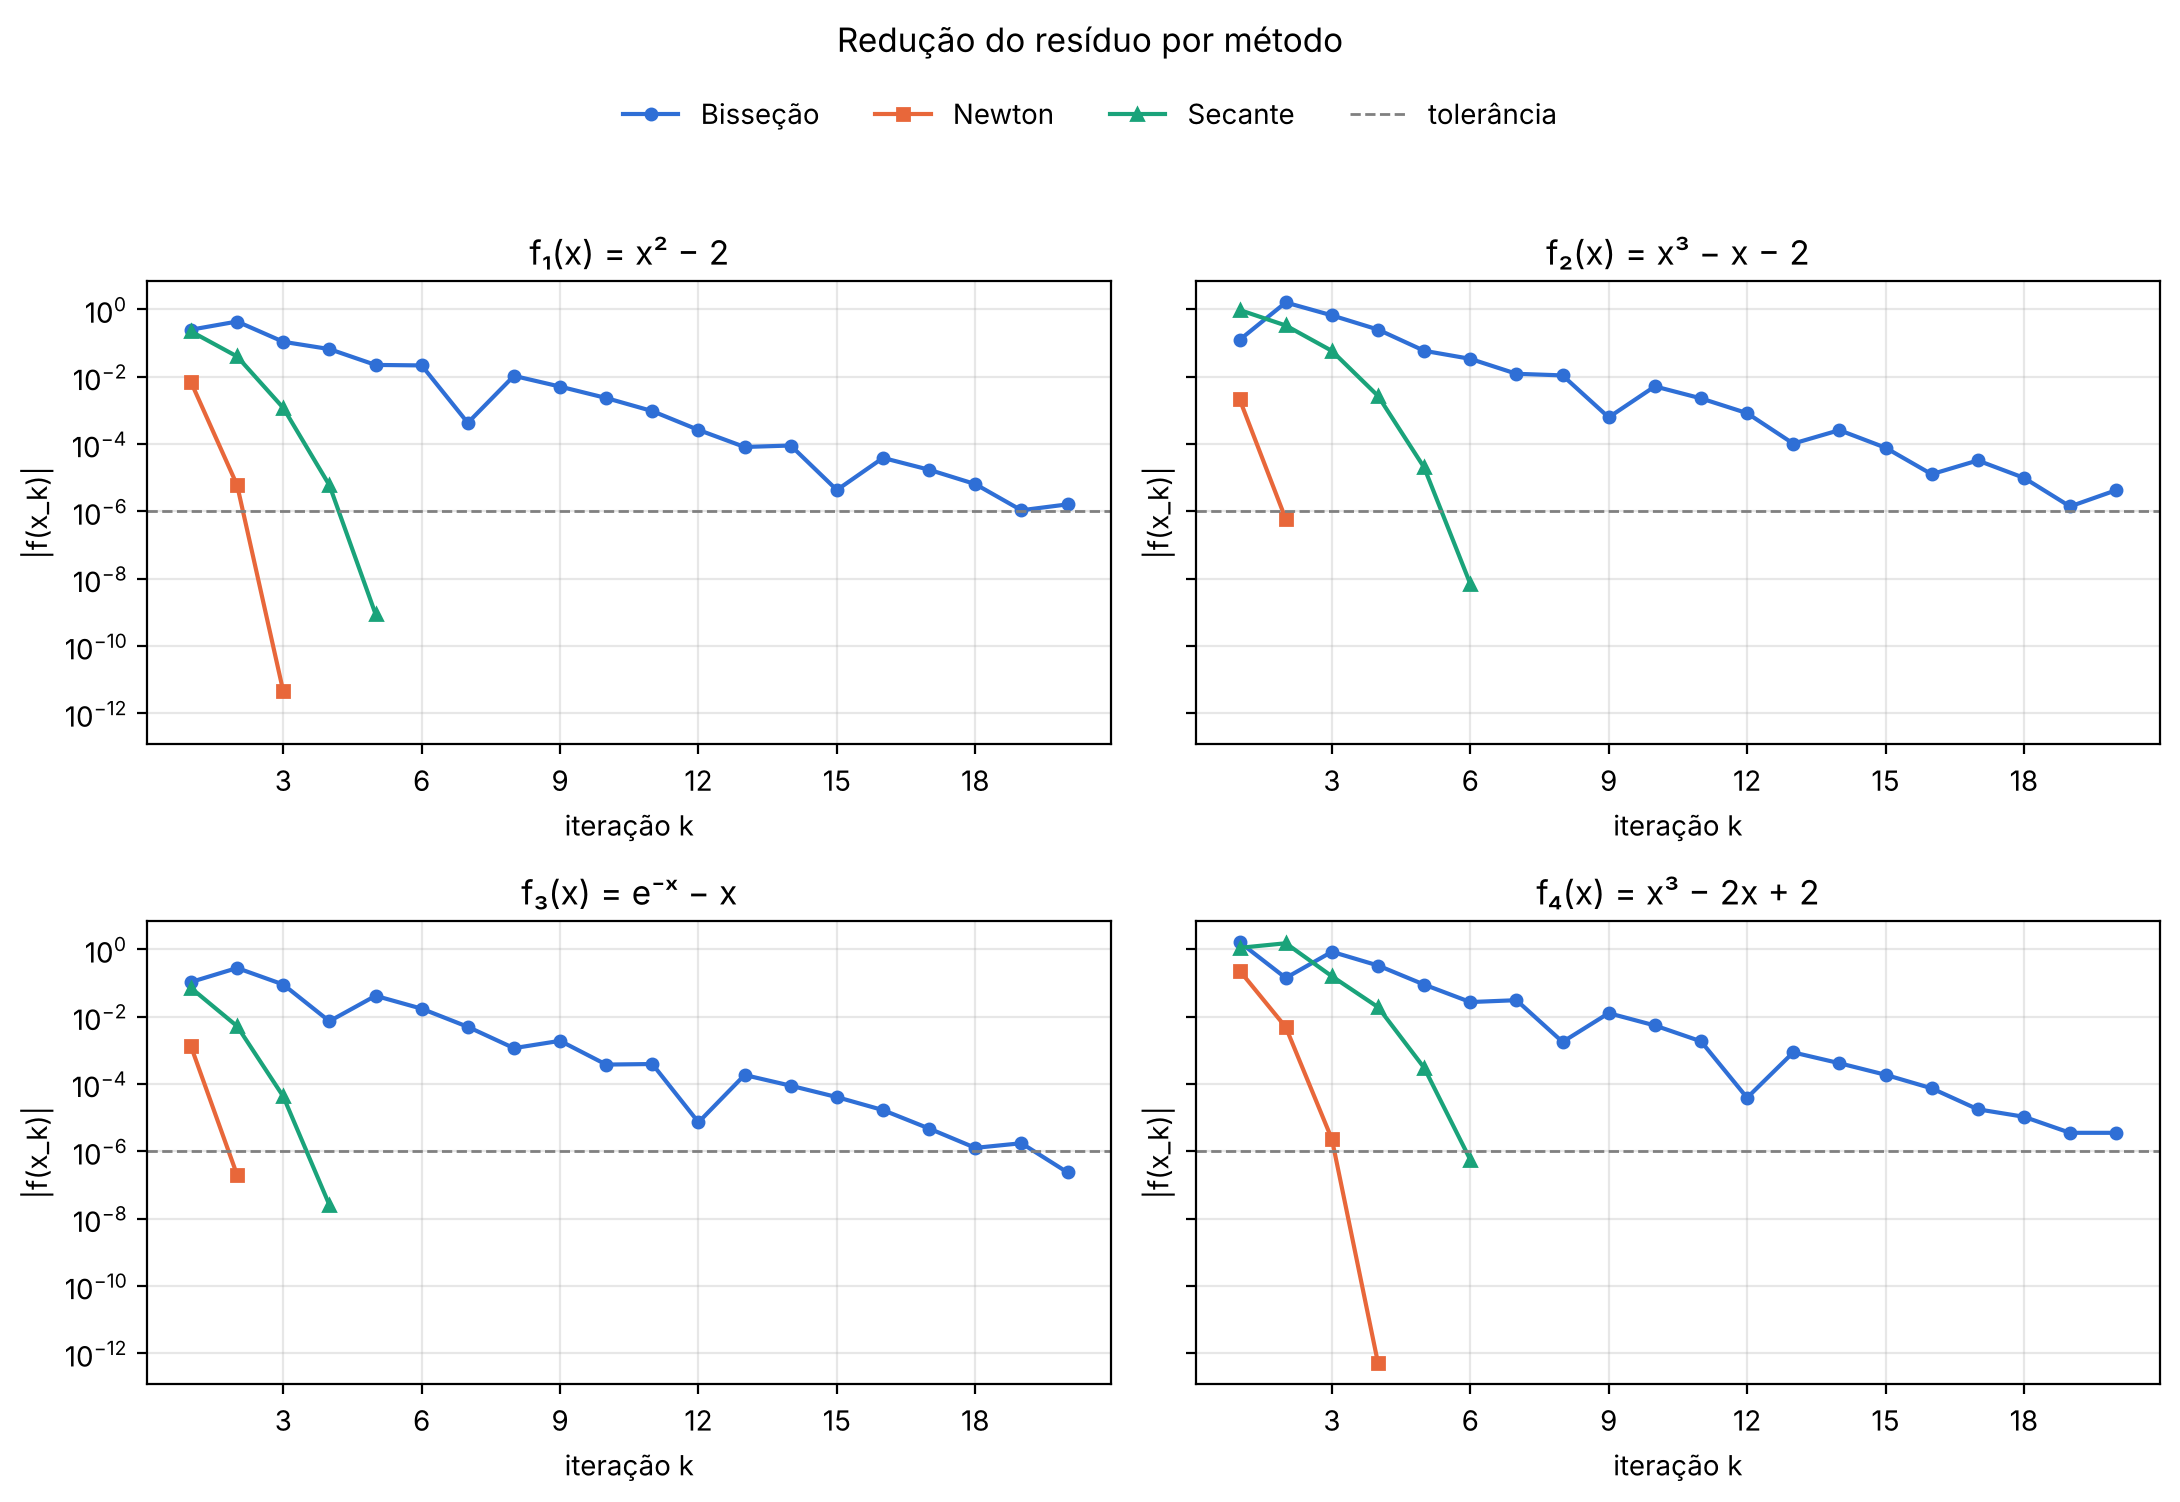

In [6]:
cores = {"Bisseção": "#2f6fd6", "Newton": "#e8673a", "Secante": "#1aa37a"}
marcadores = {"Bisseção": "o", "Newton": "s", "Secante": "^"}

fig, eixos = plt.subplots(2, 2, figsize=(11, 7.5), sharey=True)
for ax, (chave, F) in zip(eixos.flat, funcoes.items()):
    for metodo in ("Bisseção", "Newton", "Secante"):
        r = resultados[(chave, metodo)]
        res = r["hist"]["res"]
        if metodo == "Newton":
            res = res[1:]        # descarta |f(x0)|: mostra só as iterações
        elif metodo == "Secante":
            res = res[2:]        # descarta |f(x0)| e |f(x1)|
        k = np.arange(1, len(res) + 1)
        ax.semilogy(k, res, marker=marcadores[metodo], color=cores[metodo], label=metodo, ms=4)
    ax.axhline(TOL, color="gray", linestyle="--", linewidth=1, label="tolerância")
    ax.set_title(F["nome"])
    ax.set_xlabel("iteração k")
    ax.set_ylabel("|f(x_k)|")
    ax.grid(alpha=0.3, which="both")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
handles, labels = eixos[0, 0].get_legend_handles_labels()
fig.suptitle("Redução do resíduo por método", y=0.995)
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 0.96))
fig.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

## 6. Animações

Cada animação tem três painéis: a visão geral da função com a construção do método (esquerda), um zoom na iteração
atual (centro) e o histórico do resíduo com o número da iteração, o valor da aproximação e $|f(x_k)|$ (direita).
Na bisseção aparecem o intervalo que contém a raiz e sua meia largura; em Newton, as retas tangentes; na secante,
as retas que passam pelos dois últimos pontos.

As 12 animações do dashboard estão na pasta [`animacoes/`](animacoes/):

| | Bisseção | Newton | Secante |
|---|---|---|---|
| $f_1$ | [f1_bissecao.gif](animacoes/f1_bissecao.gif) | [f1_newton.gif](animacoes/f1_newton.gif) | [f1_secante.gif](animacoes/f1_secante.gif) |
| $f_2$ | [f2_bissecao.gif](animacoes/f2_bissecao.gif) | [f2_newton.gif](animacoes/f2_newton.gif) | [f2_secante.gif](animacoes/f2_secante.gif) |
| $f_3$ | [f3_bissecao.gif](animacoes/f3_bissecao.gif) | [f3_newton.gif](animacoes/f3_newton.gif) | [f3_secante.gif](animacoes/f3_secante.gif) |
| $f_4$ | [f4_bissecao.gif](animacoes/f4_bissecao.gif) | [f4_newton.gif](animacoes/f4_newton.gif) | [f4_secante.gif](animacoes/f4_secante.gif) |

A função `desenhar_quadro` desenha um quadro da animação (os três painéis descritos acima). A figura estática mostra
as três primeiras iterações de cada método: intervalos sombreados na bisseção, retas tangentes em Newton e retas
secantes na secante. A célula seguinte gera os GIFs quando `GERAR_GIFS = True`.

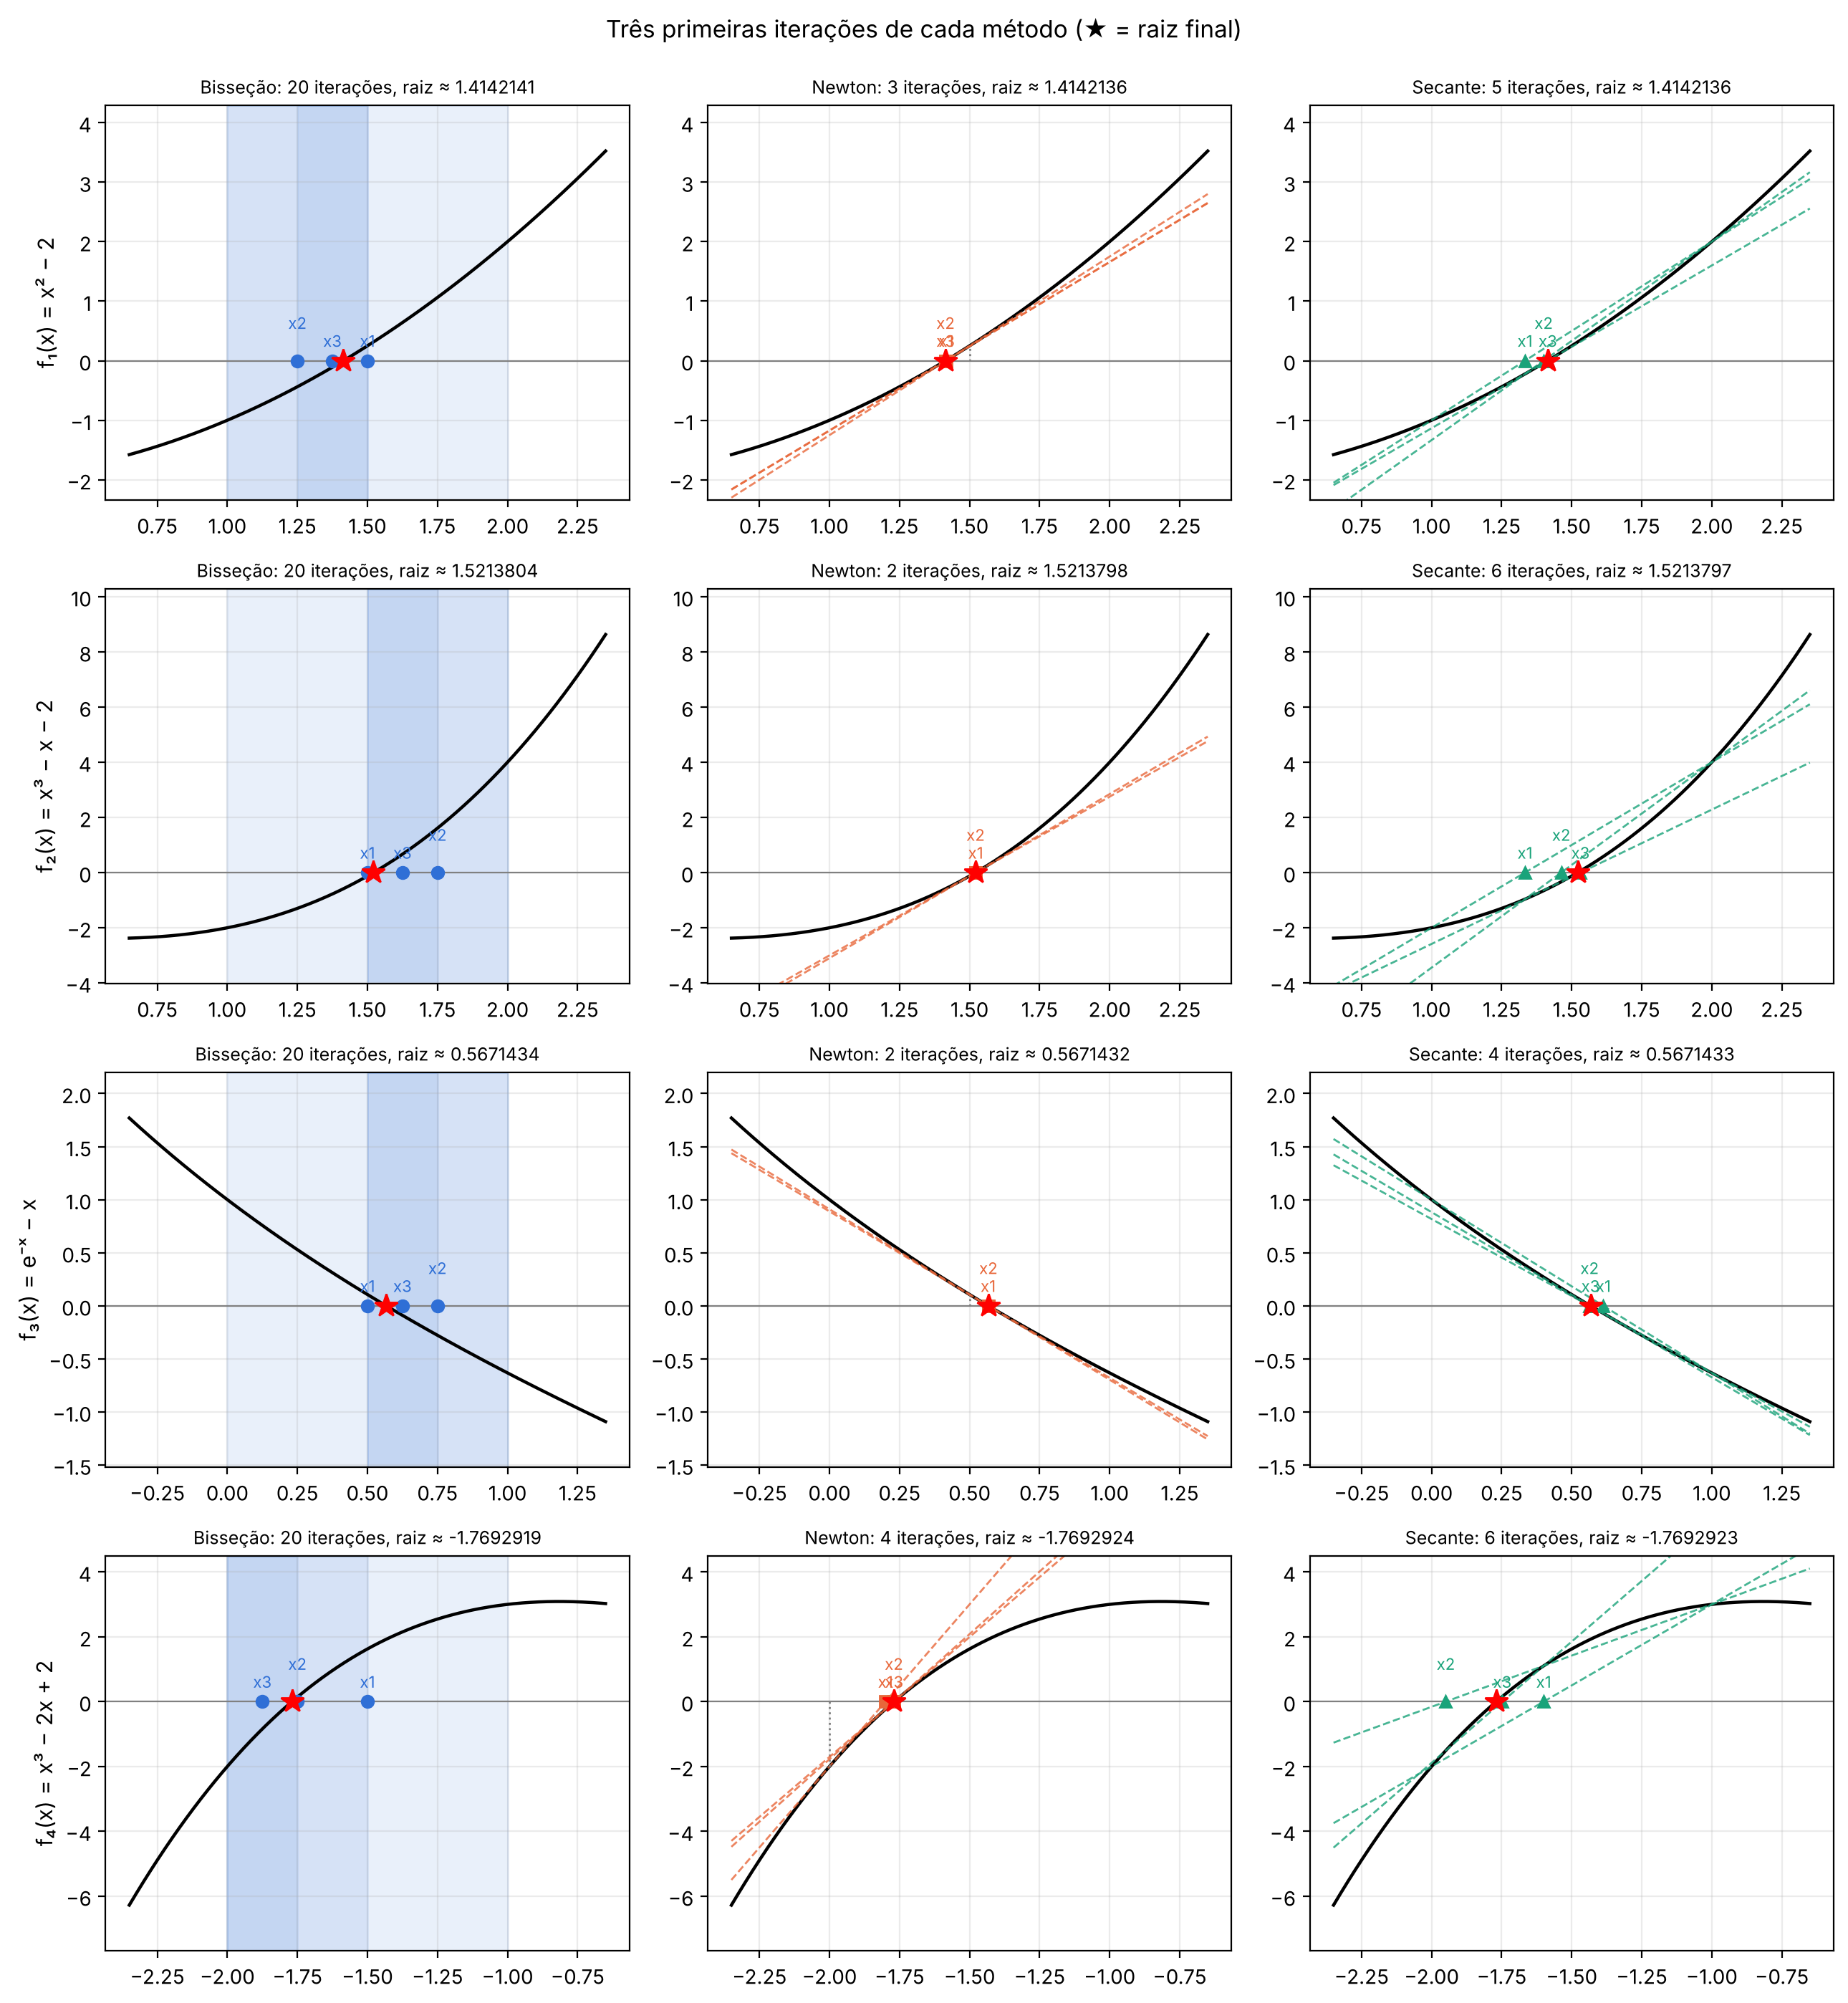

In [7]:
def desenhar_quadro(axs, chave, metodo, i):
    """Desenha o quadro i (iteração i, começando em 0) da animação nos três eixos."""
    F = funcoes[chave]; f = F["f"]
    r = resultados[(chave, metodo)]
    h = r["hist"]
    for ax in axs:
        ax.clear()

    # aproximações e resíduos de cada iteração (alinhados por k = 1, 2, ...)
    if metodo == "Bisseção":
        xs, res = h["x"], h["res"]
    elif metodo == "Newton":
        xs, res = h["x"][1:], h["res"][1:]
    else:
        xs, res = h["x"][2:], h["res"][2:]
    xk = xs[i]

    a0, b0 = F["intervalo"]
    margem = 0.35 * (b0 - a0)
    xx = np.linspace(a0 - margem, b0 + margem, 400)

    def construcao(ax, xx):
        ax.plot(xx, f(xx), color="black", lw=1.6)
        ax.axhline(0, color="gray", lw=0.8)
        if metodo == "Bisseção":
            a, b = h["a"][i], h["b"][i]
            ax.axvspan(a, b, color=cores[metodo], alpha=0.12)
            ax.plot([a, b], [f(a), f(b)], "o", color=cores[metodo], ms=5)
            ax.annotate("", xy=(b, 0), xytext=(xk, 0),
                        arrowprops=dict(arrowstyle="<->", color=cores[metodo]))
            ax.text((xk + b) / 2, 0, f" (b−a)/2 = {(b - a) / 2:.1e}", fontsize=7, va="bottom")
        elif metodo == "Newton":
            xa = h["x"][i]                       # ponto onde a tangente é traçada
            ax.plot(xx, f(xa) + F["df"](xa) * (xx - xa), "--", color=cores[metodo], lw=1.2)
            ax.plot([xa, xa], [0, f(xa)], ":", color="gray")
            ax.plot(xa, f(xa), "o", color=cores[metodo], ms=5)
        else:
            xa, xb = h["x"][i], h["x"][i + 1]    # dois últimos pontos
            incl = (f(xb) - f(xa)) / (xb - xa)
            ax.plot(xx, f(xb) + incl * (xx - xb), "--", color=cores[metodo], lw=1.2)
            ax.plot([xa, xb], [f(xa), f(xb)], "o", color=cores[metodo], ms=5)
        ax.plot(xk, 0, "*", color="red", ms=11, zorder=5)

    # painel 1: visão geral
    construcao(axs[0], xx)
    axs[0].set_title(f"{metodo} — {F['nome']}", fontsize=9)
    yv = f(xx); axs[0].set_ylim(yv.min() - 0.2 * np.ptp(yv), yv.max() + 0.2 * np.ptp(yv))

    # painel 2: zoom na iteração atual
    if metodo == "Bisseção":
        passo = (h["b"][i] - h["a"][i]) / 2
    elif metodo == "Newton":
        passo = abs(xk - h["x"][i])
    else:
        passo = abs(xk - h["x"][i + 1])
    largura = max(1.5 * passo, 2e-3)
    xz = np.linspace(xk - largura, xk + largura, 300)
    construcao(axs[1], xz)
    axs[1].set_xlim(xz[0], xz[-1])
    fz = f(xz); axs[1].set_ylim(fz.min() - 0.1 * np.ptp(fz) - 1e-12, fz.max() + 0.1 * np.ptp(fz) + 1e-12)
    axs[1].set_title("zoom na iteração atual", fontsize=9)
    axs[1].ticklabel_format(useOffset=False)

    # painel 3: histórico do resíduo
    k = np.arange(1, len(res) + 1)
    axs[2].semilogy(k[: i + 1], res[: i + 1], marker=marcadores[metodo], color=cores[metodo], ms=4)
    axs[2].axhline(TOL, color="gray", linestyle="--", lw=1)
    axs[2].set_xlim(0.5, len(res) + 0.5)
    axs[2].set_ylim(min(min(res), TOL) / 10, max(res) * 10)
    axs[2].set_xlabel("iteração k"); axs[2].grid(alpha=0.3, which="both")
    axs[2].set_title(f"k = {i + 1}   x_k = {xk:.7f}\n|f(x_k)| = {res[i]:.2e}", fontsize=9)


# Figura estática: as três primeiras iterações de cada método
def desenhar_trajetoria(ax, chave, metodo, n_passos=3):
    F = funcoes[chave]; f = F["f"]; r = resultados[(chave, metodo)]; h = r["hist"]
    a0, b0 = F["intervalo"]; margem = 0.35 * (b0 - a0)
    xx = np.linspace(a0 - margem, b0 + margem, 400)
    ax.plot(xx, f(xx), color="black", lw=1.6)
    ax.axhline(0, color="gray", lw=0.8)
    cor = cores[metodo]
    if metodo == "Bisseção":
        xs = h["x"]
        for j in range(min(n_passos, r["k"])):
            ax.axvspan(h["a"][j], h["b"][j], color=cor, alpha=0.10)
    elif metodo == "Newton":
        xs = h["x"][1:]
        for j in range(min(n_passos, r["k"])):
            xa = h["x"][j]
            ax.plot(xx, f(xa) + F["df"](xa) * (xx - xa), "--", color=cor, lw=1, alpha=0.8)
            ax.plot([xa, xa], [0, f(xa)], ":", color="gray", lw=1)
    else:
        xs = h["x"][2:]
        for j in range(min(n_passos, r["k"])):
            xa, xb = h["x"][j], h["x"][j + 1]
            incl = (f(xb) - f(xa)) / (xb - xa)
            ax.plot(xx, f(xb) + incl * (xx - xb), "--", color=cor, lw=1, alpha=0.8)
    for j, x in enumerate(xs[:n_passos]):
        ax.plot(x, 0, marker=marcadores[metodo], color=cor, ms=6, zorder=4)
        ax.annotate(f"x{j + 1}", (x, 0), textcoords="offset points", xytext=(0, 7 + 9 * (j % 2)),
                    ha="center", fontsize=8, color=cor)
    ax.plot(r["raiz"], 0, "*", color="red", ms=12, zorder=5)
    yv = f(xx); ax.set_ylim(yv.min() - 0.15 * np.ptp(yv), yv.max() + 0.15 * np.ptp(yv))
    ax.set_title(f"{metodo}: {r['k']} iterações, raiz ≈ {r['raiz']:.7f}", fontsize=9)
    ax.grid(alpha=0.25)

fig, eixos = plt.subplots(4, 3, figsize=(13, 14))
for linha, (chave, F) in zip(eixos, funcoes.items()):
    for ax, metodo in zip(linha, ("Bisseção", "Newton", "Secante")):
        desenhar_trajetoria(ax, chave, metodo)
    linha[0].set_ylabel(F["nome"], fontsize=11)
fig.suptitle("Três primeiras iterações de cada método (★ = raiz final)", y=0.995)
fig.tight_layout()
plt.show()

In [8]:
GERAR_GIFS = False   # mude para True para gerar os 12 GIFs (leva alguns minutos)
PASTA_GIFS = Path("animacoes_geradas")

nomes_arquivo = {"Bisseção": "bissecao", "Newton": "newton", "Secante": "secante"}

def gerar_gif(chave, metodo, fps=2):
    n = resultados[(chave, metodo)]["k"]
    fig, axs = plt.subplots(1, 3, figsize=(13, 4))
    fig.subplots_adjust(left=0.05, right=0.98, bottom=0.15, top=0.84, wspace=0.28)
    anim = FuncAnimation(fig, lambda i: desenhar_quadro(axs, chave, metodo, i), frames=n)
    destino = PASTA_GIFS / f"{chave}_{nomes_arquivo[metodo]}.gif"
    anim.save(destino, writer=PillowWriter(fps=fps))
    plt.close(fig)
    return destino

if GERAR_GIFS:
    PASTA_GIFS.mkdir(exist_ok=True)
    for chave in funcoes:
        for metodo in ("Bisseção", "Newton", "Secante"):
            print("gerado:", gerar_gif(chave, metodo))
else:
    print("GERAR_GIFS = False: as animações prontas estão na pasta animacoes/.")

GERAR_GIFS = False: as animações prontas estão na pasta animacoes/.


## 7. Análise

A bisseção precisou de 20 iterações em todas as funções porque os quatro intervalos têm largura 1 e a meia largura
$1/2^k$ só fica abaixo de $10^{-6}$ em $k = 20$. Newton foi o mais rápido (2 a 4 iterações), com convergência
quadrática, e a secante ficou entre os dois (4 a 6 iterações), com convergência superlinear de ordem aproximada 1,618.

Em $f_1$, $f_2$ e $f_4$ a bisseção parou pela largura do intervalo, com resíduo entre $1{,}6 \times 10^{-6}$ e
$4{,}3 \times 10^{-6}$. O erro da raiz é no máximo $9{,}5 \times 10^{-7}$, e perto da raiz o resíduo vale cerca de
$|f'(r)|$ vezes o erro. Como $|f'(r)|$ é aproximadamente 2,8, 5,9 e 7,4 nessas funções, o resíduo fica um pouco
acima da tolerância.

Em Newton, o número de iterações acompanhou a distância entre $x_0$ e a raiz: 2 iterações em $f_2$ e $f_3$, 3 em
$f_1$ e 4 em $f_4$, cujo $x_0 = -2$ está a cerca de 0,23 da raiz.

Na secante, $f_2$ e $f_4$ exigiram 6 iterações: essas cúbicas têm curvatura maior no intervalo, a primeira reta
secante se afasta mais da curva e o resíduo depois da primeira iteração é cerca de 1, contra 0,22 em $f_1$ e 0,07 em $f_3$.

O número de iterações não é o custo total: Newton avalia $f$ e $f'$ a cada passo, a secante avalia apenas $f$ e a
bisseção garante a convergência sempre que há troca de sinal no intervalo.

A célula abaixo confere os números usados nesta análise.

In [9]:
print(f"Meia largura da bisseção em k = 20: 1/2^20 = {1 / 2**20:.2e}  (em k = 19: {1 / 2**19:.2e})\n")

for chave, F in funcoes.items():
    raiz = resultados[(chave, "Newton")]["raiz"]
    res1_sec = resultados[(chave, "Secante")]["hist"]["res"][2]
    print(f"{F['nome']:<22} |f'(r)| = {abs(F['df'](raiz)):.1f}   "
          f"|x0 − r| (Newton) = {abs(F['x0'] - raiz):.2f}   "
          f"resíduo após a 1ª iteração da secante = {res1_sec:.2f}")

Meia largura da bisseção em k = 20: 1/2^20 = 9.54e-07  (em k = 19: 1.91e-06)

f₁(x) = x² − 2         |f'(r)| = 2.8   |x0 − r| (Newton) = 0.09   resíduo após a 1ª iteração da secante = 0.22
f₂(x) = x³ − x − 2     |f'(r)| = 5.9   |x0 − r| (Newton) = 0.02   resíduo após a 1ª iteração da secante = 0.96
f₃(x) = e⁻ˣ − x        |f'(r)| = 1.6   |x0 − r| (Newton) = 0.07   resíduo após a 1ª iteração da secante = 0.07
f₄(x) = x³ − 2x + 2    |f'(r)| = 7.4   |x0 − r| (Newton) = 0.23   resíduo após a 1ª iteração da secante = 1.10


## 8. Conclusão

Com os valores sugeridos, os três métodos encontraram a mesma raiz em cada função. Quando a derivada é fácil de
obter, Newton é a escolha mais econômica; quando não é, a secante é uma boa alternativa. A bisseção é útil para obter
uma aproximação com erro garantido ou um bom valor inicial para os outros dois métodos.